# Helmholtz Screening: QG PV Inversion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/helmholtz_screening.ipynb)

In quasi-geostrophic (QG) dynamics, the streamfunction $\psi$ is recovered from potential vorticity (PV) $q$ via the **Helmholtz equation**:

$$
(\nabla^2 - \lambda)\,\psi = q, \qquad \lambda = \frac{1}{L_d^2}
$$

where $L_d = \sqrt{g'H}/f_0$ is the **Rossby deformation radius**. The parameter $\lambda$ controls *screening*: how far a PV anomaly's influence extends spatially.

| Regime | $L_d$ | $\lambda$ | Character |
|--------|-------|-----------|-----------|
| Barotropic | $\infty$ | 0 | Poisson — long-range, fills the basin |
| Mesoscale | 200–500 km | moderate | Moderate screening |
| Submesoscale | 10–50 km | large | Strong screening — very local response |

This notebook demonstrates the screening effect using the spectral solver classes of gridax (spectraldiffx underneath), and the QG wrapper [`pv_inversion`](xref:api#sesmax_core.pv_inversion) of sesmax.

**What you'll learn:**

1. How the deformation radius screens the streamfunction response to an isolated PV anomaly.
2. How Dirichlet and Neumann walls differ.
3. How `pv_inversion` relates to the direct staggered solver, and how the solvers behave under JIT, vmap and grad.

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import warnings

import equinox as eqx
import gridax
import gridax_jax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import sesmax_core.gfd as gfd


jax.config.update("jax_enable_x64", True)
warnings.filterwarnings("ignore", message=r".*IProgress.*")

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p jax,equinox,gridax,gridax_jax,sesmax_core",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
gridax     : 0.2.0
gridax_jax : 0.3.0
sesmax_core: 0.1.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Setup: Isolated PV Anomaly

We place a Gaussian PV anomaly in a square basin with no-normal-flow walls ($\psi = 0$ on the boundary).

$$
q(x, y) = A \exp\!\left(-\frac{(x - x_0)^2 + (y - y_0)^2}{2\sigma^2}\right)
$$

In [4]:
nx, ny = 128, 128
Lx, Ly = 2e6, 2e6  # 2000 km × 2000 km
dx, dy = Lx / nx, Ly / ny

# PV anomaly at domain centre
amplitude = 1e-9  # s⁻²  (typical QG PV magnitude)
sigma = 200e3  # 200 km radius
x0, y0 = Lx / 2, Ly / 2

# T-point coordinates (cell centres, interior grid)
i_idx = jnp.arange(nx)[None, :] + 0.5
j_idx = jnp.arange(ny)[:, None] + 0.5
x_T = i_idx * dx
y_T = j_idx * dy

q = amplitude * jnp.exp(-((x_T - x0) ** 2 + (y_T - y0) ** 2) / (2 * sigma**2))

print(f"PV range: [{float(q.min()):.4e}, {float(q.max()):.4e}] s⁻²")

PV range: [2.0494e-20, 9.9848e-10] s⁻²


## 2. The Screening Effect

We solve $(\nabla^2 - \lambda)\psi = q$ for four values of $L_d$, sweeping from Poisson ($\lambda = 0$) to strongly screened ($L_d = 50$ km).

In [5]:
Ld_values = [np.inf, 500e3, 200e3, 50e3]  # metres
Ld_labels = [
    "$L_d = \\infty$ (Poisson)",
    "$L_d = 500$ km",
    "$L_d = 200$ km",
    "$L_d = 50$ km",
]

solutions = []
for Ld in Ld_values:
    lam = 0.0 if np.isinf(Ld) else 1.0 / Ld**2
    solver = gridax_jax.StaggeredDirichletHelmholtzSolver2D(dx=dx, dy=dy, alpha=lam)
    psi = eqx.filter_jit(solver)(q)
    solutions.append(psi)

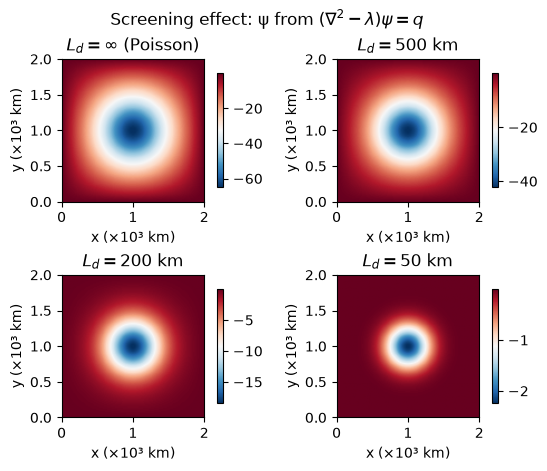

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(5.5, 4.6), constrained_layout=True)

extent = [0, Lx / 1e6, 0, Ly / 1e6]
for ax, psi, label in zip(axes.flat, solutions, Ld_labels, strict=True):
    im = ax.imshow(np.asarray(psi), origin="lower", cmap="RdBu_r", extent=extent)
    ax.set_title(label)
    ax.set_xlabel("x (×10³ km)")
    ax.set_ylabel("y (×10³ km)")
    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle("Screening effect: ψ from $(∇^2 - λ)ψ = q$")
plt.show()

As $L_d$ decreases (screening increases), the streamfunction response becomes more localised around the PV anomaly. At $L_d = 50$ km, the response barely extends beyond the Gaussian core.

## 3. Cross-Section Profiles

1-D slices through the anomaly centre show the spatial extent quantitatively.

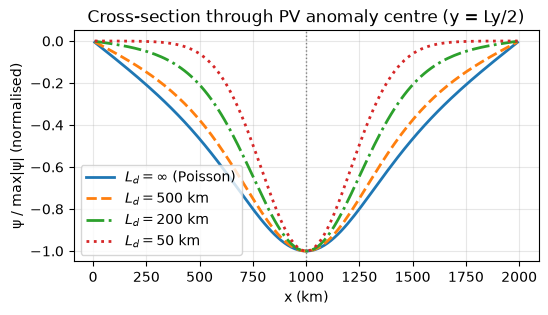

In [7]:
mid_j = ny // 2

fig, ax = plt.subplots(figsize=(6, 3))

x_km = np.asarray(x_T[mid_j, :]) / 1e3
styles = ["-", "--", "-.", ":"]

for psi, label, style in zip(solutions, Ld_labels, styles, strict=True):
    profile = np.asarray(psi[mid_j, :])
    peak = np.abs(profile).max()
    # Normalise for shape comparison
    profile_norm = profile / peak if peak > 0 else profile
    ax.plot(x_km, profile_norm, style, label=label, lw=2)

ax.set_xlabel("x (km)")
ax.set_ylabel("ψ / max|ψ| (normalised)")
ax.set_title("Cross-section through PV anomaly centre (y = Ly/2)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.axvline(x0 / 1e3, color="0.5", ls=":", lw=1)
plt.show()

## 4. Dirichlet vs Neumann Boundary Conditions

- **Dirichlet** ($\psi = 0$ on walls): no-normal-flow basin walls
- **Neumann** ($\partial\psi/\partial n = 0$ on walls): free-slip walls

For Helmholtz with $\lambda > 0$, both are well-posed (no null space).

In [8]:
Ld_compare = 200e3
lam_compare = 1.0 / Ld_compare**2

solver_dir = gridax_jax.StaggeredDirichletHelmholtzSolver2D(
    dx=dx, dy=dy, alpha=lam_compare
)
solver_neu = gridax_jax.RegularNeumannHelmholtzSolver2D(dx=dx, dy=dy, alpha=lam_compare)

psi_dir = eqx.filter_jit(solver_dir)(q)
psi_neu = eqx.filter_jit(solver_neu)(q)

diff_bc = jnp.abs(psi_dir - psi_neu)
print(f"max |ψ_Dir - ψ_Neu| = {float(diff_bc.max()):.4e}")

max |ψ_Dir - ψ_Neu| = 4.8899e-01


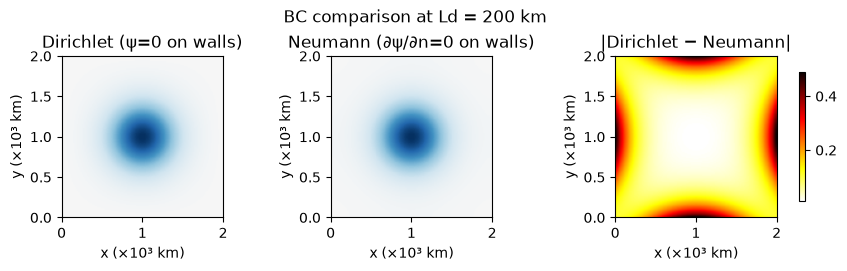

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.6), constrained_layout=True)

vmax = max(float(jnp.abs(psi_dir).max()), float(jnp.abs(psi_neu).max()))

axes[0].imshow(
    np.asarray(psi_dir),
    origin="lower",
    cmap="RdBu_r",
    extent=extent,
    vmin=-vmax,
    vmax=vmax,
)
axes[0].set_title("Dirichlet (ψ=0 on walls)")

axes[1].imshow(
    np.asarray(psi_neu),
    origin="lower",
    cmap="RdBu_r",
    extent=extent,
    vmin=-vmax,
    vmax=vmax,
)
axes[1].set_title("Neumann (∂ψ/∂n=0 on walls)")

im = axes[2].imshow(np.asarray(diff_bc), origin="lower", cmap="hot_r", extent=extent)
axes[2].set_title("|Dirichlet − Neumann|")
fig.colorbar(im, ax=axes[2], shrink=0.8)

for ax in axes:
    ax.set_xlabel("x (×10³ km)")
    ax.set_ylabel("y (×10³ km)")

fig.suptitle(f"BC comparison at Ld = {Ld_compare / 1e3:.0f} km")
plt.show()

The difference is concentrated near the domain boundaries, where the BCs differ. In the interior (far from walls), both solutions agree — the screening localises the response so boundary effects are minimal when the anomaly is well inside the domain.

## 5. Integration with sesmax

sesmax provides a convenience wrapper, [`pv_inversion`](xref:api#sesmax_core.pv_inversion), that dispatches to the spectral solvers. It solves $(\nabla^2 - \lambda)\psi = q$ and supports multi-layer batching. It solves for an **X-point** $\psi$ on the full `[Ny, Nx]` C-grid array: X node `i` sits at $x = i\,\Delta x$, the wet nodes `[1:-2, 1:-2]` are the unknowns (DST-I) and $\psi = 0$ on the wall nodes `0` and `N-2`.

In [10]:
grid = gridax.CartesianGrid2D.from_interior(nx, ny, Lx, Ly)

# q sampled at the X points of the full array
x_X = jnp.arange(nx + 2)[None, :] * dx
y_X = jnp.arange(ny + 2)[:, None] * dy
q_X = amplitude * jnp.exp(-((x_X - x0) ** 2 + (y_X - y0) ** 2) / (2 * sigma**2))
psi_sx = gfd.pv_inversion(q_X, dx, dy, lam_compare, bc="dst")

# Direct staggered solver on the T-point PV (walls on the cell faces)
psi_direct = eqx.filter_jit(solver_dir)(q)

# Average the X-point solution to the T points before comparing
psi_sx_T = gridax.Interpolation2D(grid).X_to_T(psi_sx)[1:-1, 1:-1]
diff_api = jnp.abs(psi_sx_T - psi_direct)
print(f"max |pv_inversion (X, DST-I) - T-point DST-II| = {float(diff_api.max()):.4e}")
print(f"relative diff = {float(diff_api.max() / jnp.abs(psi_direct).max()):.4e}")

max |pv_inversion (X, DST-I) - T-point DST-II| = 1.6409e-02
relative diff = 8.8975e-04


Both solve the same basin — the X-point wall nodes and the T-point cell faces are both on $x = 0, L_x$ — so the two placements agree to the $O(dx^2)$ discretisation error. Use `pv_inversion` for an X-point $\psi$ and the staggered DST-II solver for a T-point $\psi$.

## 6. JAX Ecosystem: JIT, vmap, grad

The module-class solvers are fully JAX-compatible: JIT-compiled, vmappable, and differentiable.

In [11]:
# JIT compilation
jit_solver = eqx.filter_jit(solver_dir)
_ = jit_solver(q)  # compile
psi_jit = jit_solver(q)  # fast path
print(f"JIT solve: max |ψ| = {float(jnp.abs(psi_jit).max()):.4e}")

JIT solve: max |ψ| = 1.8442e+01


In [12]:
# vmap over an ensemble of PV fields
q_ensemble = q[None, :, :] * jnp.linspace(0.5, 2.0, 5)[:, None, None]
print(f"Ensemble shape: {q_ensemble.shape}")

batch_solve = jax.vmap(jit_solver)
psi_ensemble = batch_solve(q_ensemble)
print(f"Solution shape: {psi_ensemble.shape}")
print(f"Max |ψ| per member: {[f'{float(jnp.abs(p).max()):.4e}' for p in psi_ensemble]}")

Ensemble shape: (5, 128, 128)


Solution shape: (5, 128, 128)
Max |ψ| per member: ['9.2212e+00', '1.6137e+01', '2.3053e+01', '2.9969e+01', '3.6885e+01']


In [13]:
# Differentiable: gradient of energy w.r.t. PV
def energy(q_field):
    psi = solver_dir(q_field)
    return 0.5 * jnp.sum(psi * q_field) * dx * dy


E = energy(q)
dE_dq = jax.grad(energy)(q)

print(f"Energy E = {float(E):.4e}")
print(f"dE/dq range: [{float(dE_dq.min()):.4e}, {float(dE_dq.max()):.4e}]")

Energy E = -1.4980e+03
dE/dq range: [-4.5025e+09, -2.5184e+04]


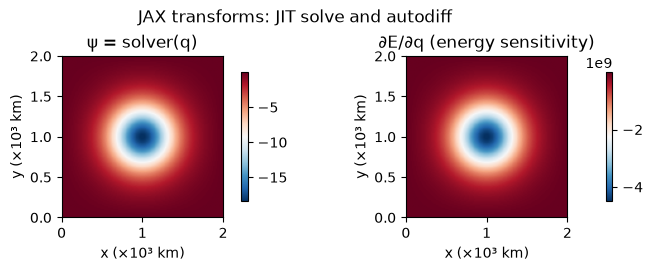

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6), constrained_layout=True)

im0 = axes[0].imshow(np.asarray(psi_jit), origin="lower", cmap="RdBu_r", extent=extent)
axes[0].set_title("ψ = solver(q)")
fig.colorbar(im0, ax=axes[0], shrink=0.8)

im1 = axes[1].imshow(np.asarray(dE_dq), origin="lower", cmap="RdBu_r", extent=extent)
axes[1].set_title("∂E/∂q (energy sensitivity)")
fig.colorbar(im1, ax=axes[1], shrink=0.8)

for ax in axes:
    ax.set_xlabel("x (×10³ km)")
    ax.set_ylabel("y (×10³ km)")

fig.suptitle("JAX transforms: JIT solve and autodiff")
plt.show()

## 7. Timing Comparison

We benchmark the module solver against the functional API at two resolutions.

In [15]:
import functools
import time


def benchmark(fn, *args, n_warmup=3, n_iter=20):
    """Time a JIT-compiled function."""
    for _ in range(n_warmup):
        fn(*args).block_until_ready()
    t0 = time.perf_counter()
    for _ in range(n_iter):
        fn(*args).block_until_ready()
    return (time.perf_counter() - t0) / n_iter


results = {}
for N in [128, 256]:
    dx_n, dy_n = Lx / N, Ly / N
    i_n = jnp.arange(N)[None, :] + 0.5
    j_n = jnp.arange(N)[:, None] + 0.5
    x_n = i_n * dx_n
    y_n = j_n * dy_n
    q_n = amplitude * jnp.exp(-((x_n - x0) ** 2 + (y_n - y0) ** 2) / (2 * sigma**2))

    # Module class
    solver_n = gridax_jax.StaggeredDirichletHelmholtzSolver2D(
        dx=dx_n, dy=dy_n, alpha=lam_compare
    )
    t_module = benchmark(eqx.filter_jit(solver_n), q_n)

    # Functional API
    solve_fn = jax.jit(
        functools.partial(
            gridax_jax.solve_helmholtz_dst, dx=dx_n, dy=dy_n, lambda_=lam_compare
        )
    )
    t_func = benchmark(solve_fn, q_n)

    results[N] = {"module": t_module, "functional": t_func}

print(f"{'Method':<20} {'128×128':>12} {'256×256':>12}")
print("-" * 46)
for method in ["module", "functional"]:
    t128 = results[128][method] * 1000
    t256 = results[256][method] * 1000
    print(f"{method:<20} {t128:>10.2f} ms {t256:>10.2f} ms")

Method                    128×128      256×256
----------------------------------------------
module                     2.26 ms       4.01 ms
functional                 1.32 ms       3.65 ms


The two methods are within a few milliseconds of each other: the module class is a thin wrapper around the functional API. The spectral solver is $O(N \log N)$ per axis transform and takes a few milliseconds on a CPU for these grids.

## Summary

| Concept | Detail |
|---------|--------|
| **Equation** | $(\nabla^2 - \lambda)\psi = q$ where $\lambda = 1/L_d^2$ |
| **Screening** | Larger $\lambda$ → more localised $\psi$ response |
| **Dirichlet** | $\psi = 0$ on walls (no-normal-flow basin) |
| **Neumann** | $\partial\psi/\partial n = 0$ (free-slip walls) |
| **Module class** | `StaggeredDirichletHelmholtzSolver2D(dx, dy, alpha)` |
| **Convenience** | `gfd.pv_inversion(q, dx, dy, lambda_)`: X-point ψ on the full array (DST-I on `[1:-2, 1:-2]`) |
| **JAX compat** | JIT, vmap, grad all work out of the box |